# mfderiv with two MUSES modules

The NJL module and CMF++ of the [MUSES](https://musesframework.io) framework solve the gap equations of their
models and tabulate $P$, $n$ and $\varepsilon$. The speed of sound is one derivative more and is usually taken from
finite differences of such a table. With mfderiv the effective potential of the model is written once, and the
solutions of the module serve as starting points. Pressure, densities and $c_s^2$ then follow to machine precision.

This notebook does this at $T=0$ for

- **CMF++**, symmetric nuclear matter with nucleons and the fields $\sigma$, $\zeta$, $\omega$ (C4 couplings),
- **the NJL module**, symmetric three-flavor quark matter with a flavor-singlet vector interaction ($\eta_V=0.7$).

The steps are the same for any mean-field module.

## 1. Run the module

Clone and build the module, then run it with the configuration in `data/`. Each run takes seconds.

```sh
# CMF++
git clone https://gitlab.com/nsf-muses/module-cmf/cmf-solver.git
cd cmf-solver && ./build.sh
./run.sh -c path/to/mfderiv/showcase/data/cmf_config.yaml

# NJL module
git clone https://gitlab.com/nsf-muses/njl.git
cd njl && cmake -S . -B build -DCMAKE_BUILD_TYPE=Release && cmake --build build
cd release && ./muses path/to/mfderiv/showcase/data/njl_config.yaml
```

The output tables of these two runs are in `data/` (`cmf_T0_symmetric.csv`, `njl_T0_symmetric.csv`), with the
column names of the modules, so the rest of this notebook needs neither module.

## 2. Add mfderiv to the project

mfderiv is header-only. With CMake

```cmake
include(FetchContent)
FetchContent_Declare(mfderiv GIT_REPOSITORY https://github.com/PsiPhiDelta/mfderiv.git GIT_TAG main)
FetchContent_MakeAvailable(mfderiv)
target_link_libraries(my_eos PRIVATE mfderiv::mfderiv)
```

## 3. Write the effective potential

The model is one function $\Phi(x,\chi)$ of the control variables $x$ and the internal variables $\chi$, generic in
the scalar type. For CMF++ at $T=0$ it is $x=(\mu_B)$ and $\chi=(\sigma,\zeta,\omega)$, from `cmf.cpp`

```cpp
struct CMF {
    // parameters of the default C4 configuration of CMF++ ...

    template <class S>
    S operator()(const mfd::VectorX<S>& x, const mfd::VectorX<S>& chi) const {
        const S& s = chi(0);
        const S& z = chi(1);
        const S& w = chi(2);
        const S m_eff = m0 + g_sigma * s + g_zeta * z;
        const S mu_eff = x(0) - g_omega * w;
        return U(s, z) - U(sigma0, zeta0) - 0.5 * m_omega * m_omega * w * w - g4 * w * w * w * w -
               gamma / 2.0 * fermi_gas(mu_eff, m_eff);
    }
};
```

and at every row of the module table

```cpp
mfd::VectorXd x(1), chi(3);
x << muB;
chi << sigma, zeta, omega;                  // the solution of the module as starting point
auto r = mfd::derivatives(cmf, x, chi, 2);  // P, n_B = dP/dmu_B, dn_B/dmu_B and the solution
double cs2 = r.dP(0) / (muB * r.d2P(0, 0));
```

The NJL potential in `njl.cpp` has the condensates $\phi_f$ and the effective chemical potential
$\mu_V=\mu-2G_Vn$ as internal variables. For neutral matter in beta equilibrium it adds $\mu_Q$ and the leptons.

## 4. Build and run

In [1]:
import pathlib
import subprocess

build = pathlib.Path('../build')
pathlib.Path('out').mkdir(exist_ok=True)


def run(*cmd):
    r = subprocess.run([str(c) for c in cmd], capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(r.stdout[-3000:] + r.stderr[-3000:])
    return r.stdout


run('cmake', '-S', '..', '-B', build, '-DCMAKE_BUILD_TYPE=Release')
run('cmake', '--build', build, '--target', 'showcase_cmf', 'showcase_njl')
bin = build / 'showcase'
print(run(bin / 'showcase_cmf', 'data/cmf_T0_symmetric.csv', 'out/cmf.csv'))
print(run(bin / 'showcase_njl', 'data/njl_T0_symmetric.csv', 'out/njl.csv'))
print(run(bin / 'showcase_njl', '--neutral', 'out/njl_neutral.csv'))

279 CMF++ points with nucleons, 0 without convergence here
deviation from CMF++ (median, max): P 1.7e-08, 2.2e-08 MeV/fm^3 | n_B 2.6e-11, 7.0e-09 | e 6.3e-12, 7.0e-09 (relative) | fields 2.2e-09, 8.5e-08 MeV

vacuum masses 367.648250 367.648250 549.479201 MeV
207 module points with quarks, 0 without convergence here
P - P_module = -4.07e-04 MeV/fm^3 (vacuum subtraction of the module), deviation from it (median, max) 8.0e-06, 1.1e-01
deviation from the module (median, max): n 8.7e-08, 7.0e-03 | e 4.3e-07, 8.0e-03 (relative) | masses 2.1e-05, 9.0e-01 | mu_V 5.5e-06, 5.3e-01 MeV

vacuum masses 367.648250 367.648250 549.479201 MeV



## 5. Nuclear matter from CMF++

At every point of the nuclear branch of the CMF++ table, mfderiv returns the same solution and pressure. Below
saturation this branch has $P<0$ and lies inside the liquid-gas transition. The speed of sound needs
$dn_B/d\mu_B$, which mfderiv takes through the implicit-function theorem. The usual alternative is the finite
difference $\Delta P/\Delta\varepsilon$ of neighbouring table rows.

saturation n0 = 0.1568 fm^-3, E/A - m_N = -16.38 MeV


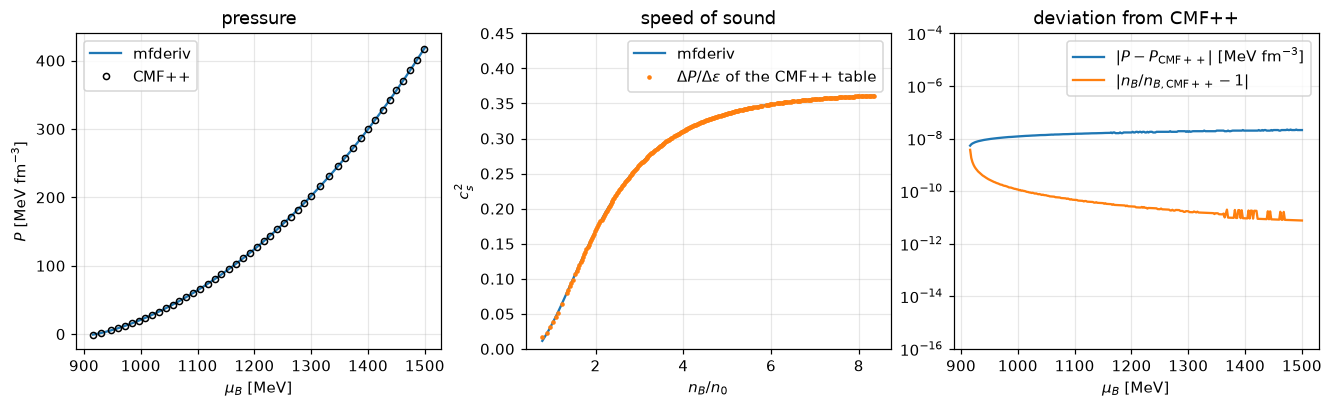

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.3})
MFD, MOD, FD = 'C0', 'k', 'C1'


def finite_difference_cs2(d, P, e):
    # central differences of the table, as one would do without mfderiv
    return np.gradient(d[P].values, d[e].values)


c = pd.read_csv('out/cmf.csv')
# CMF++ also returns points of the unstable branch of the liquid-gas transition (dn_B/dmu_B < 0), keep the nuclear one
c = c[c.cs2 > 0].sort_values('muB').reset_index(drop=True)
# saturation: the nuclear branch at P = 0, where E/A = mu_B
i = np.searchsorted(c.P.values, 0.0)
f = -c.P[i - 1] / (c.P[i] - c.P[i - 1])
n0 = c.nB[i - 1] + f * (c.nB[i] - c.nB[i - 1])
mu0 = c.muB[i - 1] + f * (c.muB[i] - c.muB[i - 1])
print(f'saturation n0 = {n0:.4f} fm^-3, E/A - m_N = {mu0 - 937.242981:.2f} MeV')

fig, ax = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
ax[0].plot(c.muB, c.P, color=MFD, label='mfderiv')
ax[0].plot(c.muB[::6], c.P_ref[::6], 'o', mfc='none', color=MOD, ms=4, label='CMF++')
ax[0].set(xlabel=r'$\mu_B$ [MeV]', ylabel=r'$P$ [MeV fm$^{-3}$]', title='pressure')
ax[0].legend()
ax[1].plot(c.nB / n0, c.cs2, color=MFD, label='mfderiv')
ax[1].plot(c.nB_ref / n0, finite_difference_cs2(c, 'P_ref', 'e_ref'), '.', color=FD, ms=4,
           label=r'$\Delta P/\Delta\varepsilon$ of the CMF++ table')
ax[1].set(xlabel=r'$n_B/n_0$', ylabel=r'$c_s^2$', title='speed of sound', ylim=(0, 0.45))
ax[1].legend()
ax[2].semilogy(c.muB, np.abs(c.P - c.P_ref), color=MFD, label=r'$|P-P_{\rm CMF++}|$ [MeV fm$^{-3}$]')
ax[2].semilogy(c.muB, np.abs(c.nB / c.nB_ref - 1) + 1e-17, color=FD, label=r'$|n_B/n_{B,\rm CMF++}-1|$')
ax[2].set(xlabel=r'$\mu_B$ [MeV]', title='deviation from CMF++', ylim=(1e-16, 1e-4))
ax[2].legend()
plt.show()

## 6. Quark matter from the NJL module

The module run follows the chirally broken solution into quark matter. mfderiv reproduces its pressure up to the
constant vacuum subtraction of the module, and its densities and masses to its integration accuracy. The dashed
curve is the same model in neutral matter in beta equilibrium, which the module table does not contain.

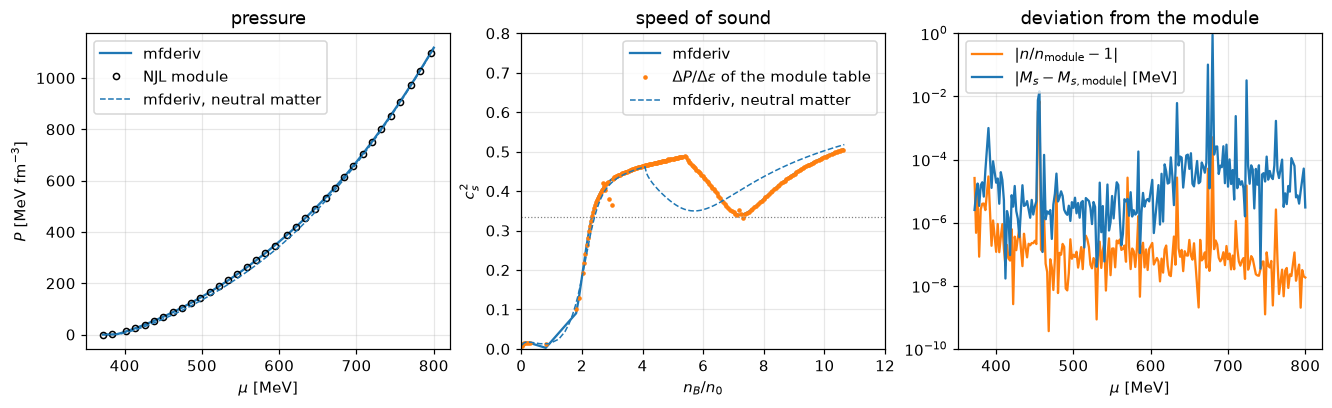

P - P_module = -4.07e-04 MeV/fm^3 at all points (vacuum subtraction of the module)


In [3]:
q = pd.read_csv('out/njl.csv').sort_values('mu').reset_index(drop=True)
qn = pd.read_csv('out/njl_neutral.csv')
offset = np.median(q.P - q.P_ref)
nsat = 0.16  # fm^-3, for the n_B axis

fig, ax = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
ax[0].plot(q.mu, q.P, color=MFD, label='mfderiv')
ax[0].plot(q.mu[::6], q.P_ref[::6] + offset, 'o', mfc='none', color=MOD, ms=4, label='NJL module')
ax[0].plot(qn.mu, qn.P, '--', color=MFD, lw=1, label='mfderiv, neutral matter')
ax[0].set(xlabel=r'$\mu$ [MeV]', ylabel=r'$P$ [MeV fm$^{-3}$]', title='pressure')
ax[0].legend()
ax[1].plot(q.n / 3 / nsat, q.cs2, color=MFD, label='mfderiv')
ax[1].plot(q.n_ref / 3 / nsat, finite_difference_cs2(q, 'P_ref', 'e_ref'), '.', color=FD, ms=4,
           label=r'$\Delta P/\Delta\varepsilon$ of the module table')
ax[1].plot(qn.n / 3 / nsat, qn.cs2, '--', color=MFD, lw=1, label='mfderiv, neutral matter')
ax[1].axhline(1 / 3, color='0.5', lw=0.8, ls=':')
ax[1].set(xlabel=r'$n_B/n_0$', ylabel=r'$c_s^2$', title='speed of sound', xlim=(0, 12), ylim=(0, 0.8))
ax[1].legend()
ax[2].semilogy(q.mu, np.abs(q.n / q.n_ref - 1), color=FD, label=r'$|n/n_{\rm module}-1|$')
ax[2].semilogy(q.mu, np.abs(q.M_s - q.M_s_ref), color=MFD, label=r'$|M_s-M_{s,\rm module}|$ [MeV]')
ax[2].set(xlabel=r'$\mu$ [MeV]', title='deviation from the module', ylim=(1e-10, 1))
ax[2].legend()
plt.show()
print(f'P - P_module = {offset:.2e} MeV/fm^3 at all points (vacuum subtraction of the module)')

## Summary

- mfderiv reproduces both modules from their own solutions, CMF++ to the precision of its output and the NJL
  module to the accuracy of its momentum integrals.
- $c_s^2$ follows at every point from one call, at the cost of a Newton step per derivative order, with no
  table, grid spacing or smoothing. Finite differences of a dense and smooth table come close, but they pick up
  every bit of scatter of the module, as near $3n_0$ in the NJL table, and depend on the grid spacing at kinks
  such as the onset of strange quarks.
- The potential is the only model input, so the same lines give susceptibilities, $c_s^2$ at fixed entropy per
  baryon at finite temperature, or higher derivatives, see the README.